# 04 - Proyección de costos
Proyección de los precios de las materias primas y, a partir del modelo de relación, del costo futuro de cada equipo con un escenario esperado, uno bajo y uno alto.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PROCESSED = Path("../data/processed")

historico = pd.read_csv(
    DATA_PROCESSED / "historico_equipos_limpio.csv",
    parse_dates=["Date"]
)

In [2]:
mensual = historico.set_index("Date").resample("MS").mean()

print(mensual.shape)
display(mensual.head())
display(mensual.tail())

(164, 5)


,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
Date,,,,,
2010-01-01,77.013000,547.000000,2234.325000,451.818000,945.189500
2010-02-01,74.790000,538.000000,2048.575000,444.143500,886.575000
2010-03-01,79.931304,606.630435,2204.130435,501.005217,965.705652
2010-04-01,85.753810,682.976190,2313.083333,562.120476,1025.756667
2010-05-01,76.997619,679.642857,2048.666667,558.783333,932.173333


,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
Date,,,,,
2023-04-01,83.368947,603.885789,2336.763158,503.402105,1009.561053
2023-05-01,75.694783,550.593913,2271.586957,457.468696,964.018261
2023-06-01,74.978636,541.775909,2180.738636,449.975909,931.185455
2023-07-01,80.160000,554.357619,2152.011905,460.872381,929.810476
2023-08-01,85.104348,556.303913,2133.021739,461.035217,927.660870


In [3]:
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from sklearn.metrics import mean_absolute_percentage_error

meses_prueba = 12
entrenamiento = mensual.iloc[:-meses_prueba]
prueba = mensual.iloc[-meses_prueba:]

serie = "Price_Y"

modelo_ets = ETSModel(
    entrenamiento[serie],
    error="add",
    trend="add",
    damped_trend=True,
    seasonal="add",
    seasonal_periods=12,
).fit(disp=False)
pronostico_ets = modelo_ets.forecast(meses_prueba)

pronostico_ingenuo = pd.Series(entrenamiento[serie].iloc[-1], index=prueba.index)

print(f"MAPE suavizado exponencial: {mean_absolute_percentage_error(prueba[serie], pronostico_ets):.2%}")
print(f"MAPE método ingenuo:        {mean_absolute_percentage_error(prueba[serie], pronostico_ingenuo):.2%}")

MAPE suavizado exponencial: 12.45%
MAPE método ingenuo:        6.67%


In [4]:
modelo_ets_sin_tendencia = ETSModel(
    entrenamiento[serie],
    error="add",
    trend=None,
    seasonal="add",
    seasonal_periods=12,
).fit(disp=False)
pronostico_sin_tendencia = modelo_ets_sin_tendencia.forecast(meses_prueba)

print(f"MAPE suavizado sin tendencia: {mean_absolute_percentage_error(prueba[serie], pronostico_sin_tendencia):.2%}")

MAPE suavizado sin tendencia: 6.03%


In [5]:
def evaluar_metodos(serie, datos, cortes, horizonte=12):
    """Compara los métodos de pronóstico de una serie en varias ventanas y devuelve el MAPE de cada uno."""
    resultados = []

    for corte in cortes:
        entrenamiento = datos.loc[:corte, serie]
        prueba = datos.loc[corte:, serie].iloc[1:horizonte + 1]

        pronosticos = {
            "Ingenuo": pd.Series(entrenamiento.iloc[-1], index=prueba.index),
            "ETS con tendencia": ETSModel(entrenamiento, error="add", trend="add", damped_trend=True,
                                          seasonal="add", seasonal_periods=12).fit(disp=False).forecast(horizonte),
            "ETS sin tendencia": ETSModel(entrenamiento, error="add", trend=None,
                                          seasonal="add", seasonal_periods=12).fit(disp=False).forecast(horizonte),
        }

        for metodo, pronostico in pronosticos.items():
            resultados.append({
                "serie": serie,
                "corte": corte,
                "metodo": metodo,
                "mape": mean_absolute_percentage_error(prueba, pronostico),
            })

    return pd.DataFrame(resultados)

In [6]:
cortes = ["2019-08-01", "2020-08-01", "2021-08-01", "2022-08-01"]

resultados = pd.concat([
    evaluar_metodos(serie, mensual, cortes)
    for serie in ["Price_X", "Price_Y", "Price_Z"]
])

tabla_mape = resultados.pivot_table(index="serie", columns="metodo", values="mape", aggfunc="mean")
display((tabla_mape * 100).round(2))

metodo,ETS con tendencia,ETS sin tendencia,Ingenuo
serie,,,
Price_X,23.21,26.64,25.29
Price_Y,16.93,15.37,15.30
Price_Z,9.24,10.84,10.60


In [7]:
import numpy as np

def error_por_horizonte(serie, tendencia, datos, cortes, horizonte=12):
    """Calcula el error porcentual promedio para cada mes adelante (1 a horizonte)."""
    errores = []

    for corte in cortes:
        entrenamiento = datos.loc[:corte, serie]
        prueba = datos.loc[corte:, serie].iloc[1:horizonte + 1]

        modelo = ETSModel(entrenamiento, error="add", trend=tendencia, damped_trend=tendencia is not None,
                          seasonal="add", seasonal_periods=12).fit(disp=False)
        pronostico = modelo.forecast(horizonte)

        errores.append(np.abs(prueba.values - pronostico.values) / prueba.values * 100)

    return pd.Series(np.mean(errores, axis=0), index=range(1, horizonte + 1))

,Price_X,Price_Y,Price_Z
1,7.5,3.4,4.0
2,9.2,4.2,5.0
3,9.0,8.9,3.4
4,11.7,10.4,4.4
5,15.7,13.0,6.4
6,14.7,11.6,9.1
7,38.0,13.2,13.3
8,48.0,19.5,15.2
9,41.7,24.7,12.6
10,33.7,22.4,11.7


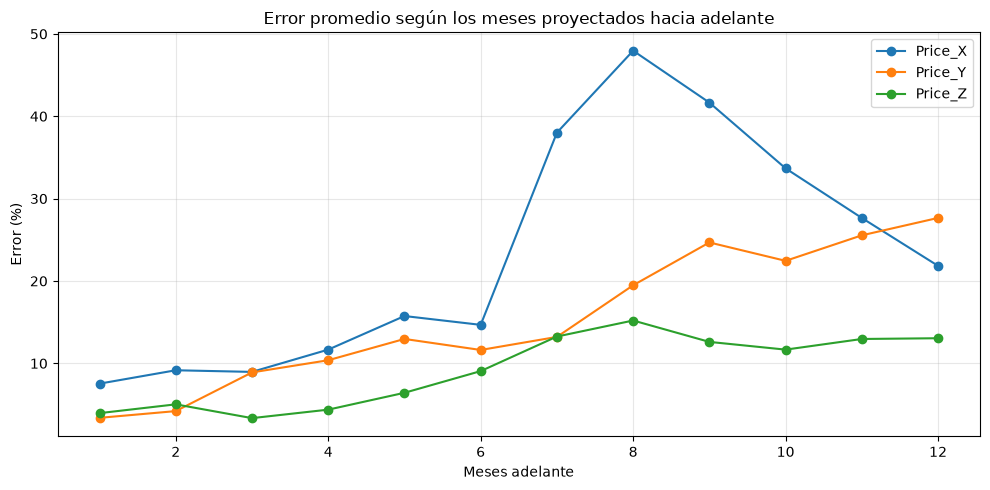

In [8]:
metodo_elegido = {"Price_X": "add", "Price_Y": None, "Price_Z": "add"}

errores_horizonte = pd.DataFrame({
    serie: error_por_horizonte(serie, tendencia, mensual, cortes)
    for serie, tendencia in metodo_elegido.items()
})

display(errores_horizonte.round(1))

errores_horizonte.plot(marker="o", figsize=(10, 5))
plt.title("Error promedio según los meses proyectados hacia adelante")
plt.xlabel("Meses adelante")
plt.ylabel("Error (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../reports/figures/05_error_por_horizonte.png", dpi=150)
plt.show()

## Horizonte de predicción

1. El error crece a medida que se proyectan más meses. Hasta el mes 6 se mantiene controlado (máximo cerca de 15%), pero desde el mes 7 se dispara, sobre todo en el precio de X.
2. El mayor error de X (38% y 48%) ocurre en los meses 7 y 8 de la ventana que aprendió hasta agosto de 2019, es decir, en marzo y abril de 2020. Coincide con la pandemia del COVID-19, cuando el petróleo WTI llegó a negociarse a precios negativos el 20 de abril de 2020 ([EIA](https://www.eia.gov/todayinEnergy/detail.php?id=46336)).
3. Eventos como este no se pueden prever con datos históricos. Por eso se define un horizonte de 6 meses y se recomienda actualizar la proyección cada mes con los datos nuevos.

In [9]:
horizonte_final = 6
proyecciones_mp = {}

for serie, tendencia in metodo_elegido.items():
    modelo_final = ETSModel(mensual[serie], error="add", trend=tendencia, damped_trend=tendencia is not None,
                            seasonal="add", seasonal_periods=12).fit(disp=False)
    prediccion = modelo_final.get_prediction(start=len(mensual), end=len(mensual) + horizonte_final - 1)
    proyecciones_mp[serie] = prediccion.summary_frame(alpha=0.05)[["mean", "pi_lower", "pi_upper"]]

for serie, tabla in proyecciones_mp.items():
    print(serie)
    display(tabla.round(2))

Price_X


,mean,pi_lower,pi_upper
2023-09-01,86.32,75.42,97.22
2023-10-01,87.60,71.10,104.09
2023-11-01,86.29,64.93,107.65
2023-12-01,84.92,59.10,110.74
2024-01-01,86.20,56.20,116.19
2024-02-01,89.11,55.17,123.05


Price_Y


,mean,pi_lower,pi_upper
2023-09-01,552.45,489.26,615.64
2023-10-01,537.74,448.38,627.10
2023-11-01,528.11,418.67,637.55
2023-12-01,543.07,416.70,669.44
2024-01-01,553.95,412.66,695.24
2024-02-01,563.71,408.94,718.48


Price_Z


,mean,pi_lower,pi_upper
2023-09-01,2133.27,1939.07,2327.47
2023-10-01,2139.21,1846.80,2431.62
2023-11-01,2114.41,1737.28,2491.53
2023-12-01,2122.25,1667.69,2576.82
2024-01-01,2158.20,1631.37,2685.02
2024-02-01,2169.99,1575.10,2764.87


In [10]:
x_completo = pd.read_csv(DATA_PROCESSED / "x_limpio.csv", parse_dates=["Date"])
x_mensual_real = x_completo.set_index("Date").resample("MS").mean()["Price"]

proyeccion_x = proyecciones_mp["Price_X"]
comparacion_x = proyeccion_x.copy()
comparacion_x["real"] = x_mensual_real.loc[proyeccion_x.index]
comparacion_x["dentro_del_intervalo"] = comparacion_x["real"].between(comparacion_x["pi_lower"], comparacion_x["pi_upper"])

display(comparacion_x.round(2))
print(f"MAPE de la proyección de X: {mean_absolute_percentage_error(comparacion_x['real'], comparacion_x['mean']):.2%}")

,mean,pi_lower,pi_upper,real,dentro_del_intervalo
2023-09-01,86.32,75.42,97.22,92.59,True
2023-10-01,87.60,71.10,104.09,88.70,True
2023-11-01,86.29,64.93,107.65,82.03,True
2023-12-01,84.92,59.10,110.74,77.32,True
2024-01-01,86.20,56.20,116.19,79.15,True
2024-02-01,89.11,55.17,123.05,81.72,True


MAPE de la proyección de X: 6.83%


## Validación de X con datos reales

1. El archivo de X tiene precios reales hasta abril de 2024, así que se comparó la proyección de X con lo que realmente pasó. El error (MAPE) fue de 6,83% y el precio real quedó dentro del intervalo de predicción en los 6 meses.
2. Esta comparación es solo una validación: la proyección oficial de los equipos usa X proyectada, porque en agosto de 2023 esos precios todavía no se conocían. Usar los precios reales sería usar información del futuro.

In [11]:
import statsmodels.api as sm

materias_primas = ["Price_X", "Price_Y", "Price_Z"]
X_reg = sm.add_constant(historico[materias_primas])

recetas = {
    "Equipo 1": sm.OLS(historico["Price_Equipo1"], X_reg).fit(),
    "Equipo 2": sm.OLS(historico["Price_Equipo2"], X_reg).fit(),
}

def escenario(columna):
    return pd.DataFrame({
        "const": 1.0,
        "Price_X": proyecciones_mp["Price_X"][columna],
        "Price_Y": proyecciones_mp["Price_Y"][columna],
        "Price_Z": proyecciones_mp["Price_Z"][columna],
    })

proyeccion_equipos = {}
for equipo, receta in recetas.items():
    proyeccion_equipos[equipo] = pd.DataFrame({
        "esperado": receta.predict(escenario("mean")),
        "bajo": receta.predict(escenario("pi_lower")),
        "alto": receta.predict(escenario("pi_upper")),
    })
    print(equipo)
    display(proyeccion_equipos[equipo].round(2))

Equipo 1


,esperado,bajo,alto
2023-09-01,459.21,406.47,511.95
2023-10-01,447.69,372.90,522.49
2023-11-01,439.72,347.89,531.56
2023-12-01,451.42,345.15,557.69
2024-01-01,460.39,341.35,579.42
2024-02-01,468.78,338.16,599.39


Equipo 2


,esperado,bajo,alto
2023-09-01,923.48,834.17,1012.79
2023-10-01,920.93,788.38,1053.49
2023-11-01,909.03,740.00,1078.06
2023-12-01,916.21,714.30,1118.11
2024-01-01,932.22,699.93,1164.50
2024-02-01,940.38,679.67,1201.09


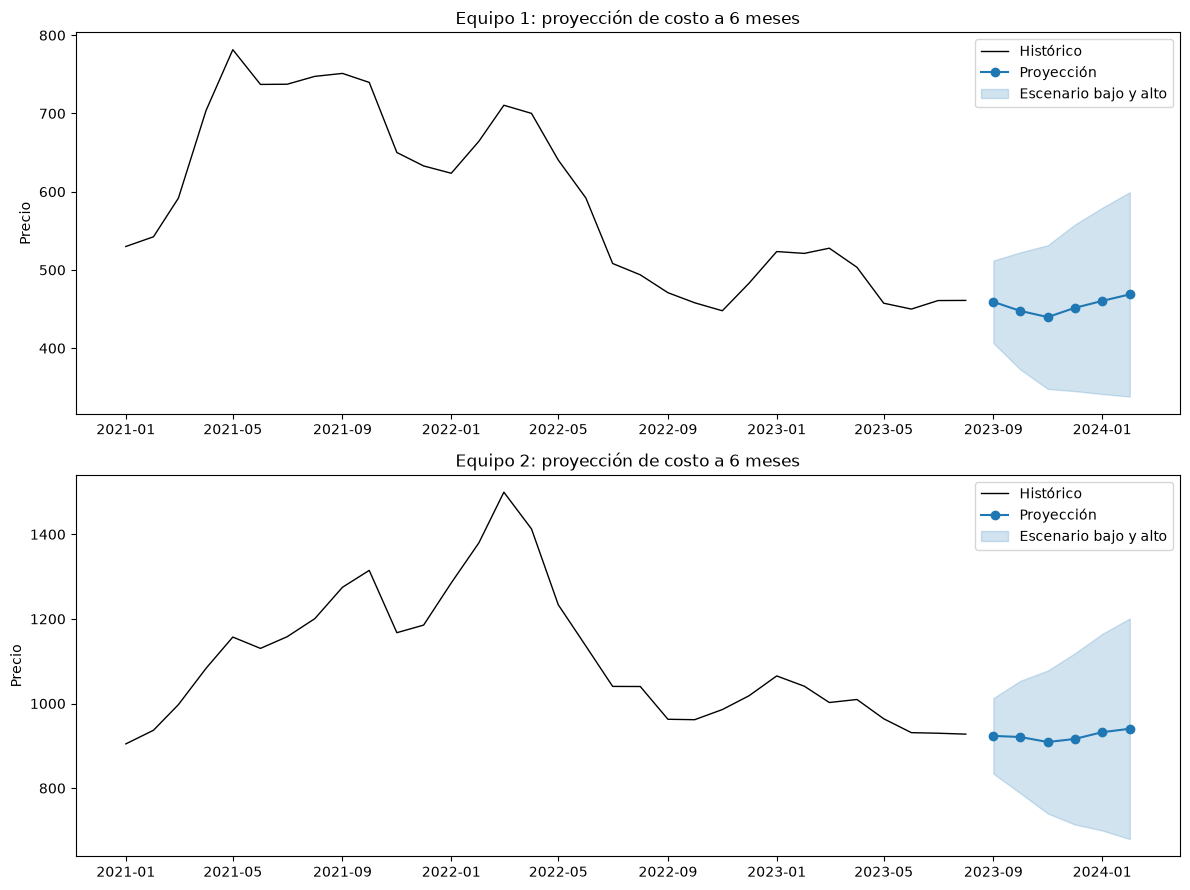

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

for ax, (equipo, columna) in zip(axes, [("Equipo 1", "Price_Equipo1"), ("Equipo 2", "Price_Equipo2")]):
    proyeccion = proyeccion_equipos[equipo]
    historico_reciente = mensual[columna].loc["2021-01-01":]

    ax.plot(historico_reciente.index, historico_reciente, label="Histórico", color="black", linewidth=1)
    ax.plot(proyeccion.index, proyeccion["esperado"], label="Proyección", color="tab:blue", marker="o")
    ax.fill_between(proyeccion.index, proyeccion["bajo"], proyeccion["alto"], color="tab:blue", alpha=0.2, label="Escenario bajo y alto")
    ax.set_title(f"{equipo}: proyección de costo a 6 meses")
    ax.set_ylabel("Precio")
    ax.legend()

plt.tight_layout()
plt.savefig("../reports/figures/06_proyeccion_equipos.png", dpi=150)
plt.show()

In [13]:
tabla_final = pd.concat(proyeccion_equipos, axis=1).round(2)
tabla_final.index.name = "Mes"
tabla_final.to_csv("../reports/proyeccion_costos_equipos.csv")
display(tabla_final)

Equipo 1                 Equipo 2                 
           esperado    bajo    alto esperado    bajo     alto
Mes                                                          
2023-09-01   459.21  406.47  511.95   923.48  834.17  1012.79
2023-10-01   447.69  372.90  522.49   920.93  788.38  1053.49
2023-11-01   439.72  347.89  531.56   909.03  740.00  1078.06
2023-12-01   451.42  345.15  557.69   916.21  714.30  1118.11
2024-01-01   460.39  341.35  579.42   932.22  699.93  1164.50
2024-02-01   468.78  338.16  599.39   940.38  679.67  1201.09

## Conclusión de la proyección de costos

1. Para septiembre de 2023, el costo esperado del Equipo 1 es de 459,21 (escenario bajo 406,47 y alto 511,95) y el del Equipo 2 es de 923,48 (escenario bajo 834,17 y alto 1.012,79).
2. Para febrero de 2024, el costo esperado del Equipo 1 es de 468,78 (escenario bajo 338,16 y alto 599,39) y el del Equipo 2 es de 940,38 (escenario bajo 679,67 y alto 1.201,09).
3. El costo esperado del Equipo 1 baja un poco en octubre y noviembre por la estacionalidad heredada de Y.
4. El escenario bajo y el alto suponen que X, Y y Z llegan a su extremo al mismo tiempo, por lo que son conservadores. Se abren mes a mes por la mayor incertidumbre. Se recomienda usar el escenario alto como tope del presupuesto y actualizar la proyección cada mes.
5. La proyección usa X proyectada, con la información disponible en agosto de 2023. Los precios reales de X se usaron solo para validar la proyección.